# IRWA 2026 - Part 1: Text Processing and Exploratory Data Analysis

The pre-processing functions live in `myapp/search/preprocessing.py`, so that later parts (indexing, ranking, the web
app) process documents and queries with exactly the same pipeline. This notebook applies them to the corpus, saves the
processed corpus, inspects the validation labels and runs the exploratory data analysis.
Run instructions: see `README.md` in this folder.

## 0. Setup

Imports, paths (the repository root is located automatically, so the notebook runs from any working directory) and plot helpers. Figures are saved to `project_progress/part_1/figures/`.

In [1]:
import json
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# repository root = first folder (from the working directory upwards) that contains web_app.py and myapp/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "web_app.py").exists() and (p / "myapp").is_dir())
sys.path.insert(0, str(REPO_ROOT))

from myapp.search.objects import Document
from myapp.search.preprocessing import (DETAILS_EXCLUDED_KEYS, NUMERIC_FIELDS, OUTPUT_FIELDS, TEXT_FIELDS,
                                        build_terms, fix_mojibake, load_processed_corpus, normalize_text,
                                        parse_product_details, preprocess_corpus, preprocess_query, recover_brand,
                                        save_processed_corpus, tokenize)

DATA_PATH = REPO_ROOT / "data" / "fashion_products_dataset.json"
LABELS_PATH = REPO_ROOT / "data" / "validation_labels.csv"
PROCESSED_PATH = REPO_ROOT / "data" / "processed_corpus.jsonl"      # full processed corpus (data/ is git-ignored)
PART_DIR = REPO_ROOT / "project_progress" / "part_1"
FIG_DIR = PART_DIR / "figures"
OUT_DIR = PART_DIR / "output"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42          # used for every sample (NER, word clouds)
SAVE_FIGURES = True

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
print("repository root:", REPO_ROOT)

repository root: /home/darcytrobertson/uni/irwa-merge


In [2]:
# Plot style: light surface, recessive grid, one blue for single-series charts
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "axes.titlecolor": TEXT, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": TEXT_2, "ytick.color": TEXT_2, "legend.frameon": False,
    "figure.dpi": 110, "font.size": 10,
})


def savefig(fig, name):
    """Save a figure as FIG_DIR/<name>.png (if SAVE_FIGURES) so it can be reused in the report."""
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def barh(series, title, xlabel, name, color=BLUE, fmt="{:,.0f}"):
    """Horizontal bar chart of a Series (first element at the top) with value labels."""
    series = series.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(series) + 1))
    bars = ax.barh(series.index.astype(str), series.values, color=color, height=0.7)
    ax.bar_label(bars, labels=[fmt.format(v) for v in series.values], padding=3, color=TEXT_2, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    savefig(fig, name)
    plt.show()


def hist(values, title, xlabel, name, bins=50, color=BLUE, log=False, median=True):
    """Histogram of a numeric Series, with a dashed line at the median."""
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.hist(values, bins=bins, color=color, edgecolor="#fcfcfb", linewidth=0.6, log=log)
    if median:
        ax.axvline(np.median(values), color=TEXT, linestyle="--", linewidth=1, label=f"median = {np.median(values):,.1f}")
        ax.legend()
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("number of products")
    ax.grid(axis="x", visible=False)
    savefig(fig, name)
    plt.show()

## 1. Load the corpus

Loads the raw JSON documents and checks that every field required in the output exists and that `pid` is unique.

In [3]:
with open(DATA_PATH, encoding="utf-8") as f:
    raw_docs = json.load(f)
raw = pd.DataFrame(raw_docs)
print(f"{len(raw):,} documents, {raw['pid'].nunique():,} unique pids")
print("fields:", list(raw.columns))
missing_fields = sorted(set(OUTPUT_FIELDS) - set(raw.columns))
assert not missing_fields, f"required fields missing from the corpus: {missing_fields}"
assert raw["pid"].is_unique
raw.head(3)

28,080 documents, 28,080 unique pids
fields: ['_id', 'actual_price', 'average_rating', 'brand', 'category', 'crawled_at', 'description', 'discount', 'images', 'out_of_stock', 'pid', 'product_details', 'seller', 'selling_price', 'sub_category', 'title', 'url']


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,1612987911000,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,69% off,[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-10...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76a...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,66% off,[https://rukminim1.flixcart.com/image/128/128/kfyasnk0/track-pant/g/5/y/s-19...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Drawstring, Elastic'}, {'Pockets':...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue-track-pants/p/itmfczez7v6rzwe...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,68% off,[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/e/c/s/xl-1...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itm1eee3c...


### 1.1 Missing values

Counts missing values per field (`None`, empty strings and empty lists count as missing).

In [4]:
def is_missing(v):
    """True for None, NaN and empty strings / lists / dicts."""
    if isinstance(v, (str, list, dict)):
        return len(v) == 0 if not isinstance(v, str) else v.strip() == ""
    return v is None or (isinstance(v, float) and np.isnan(v))

missing = raw.apply(lambda col: col.map(is_missing).sum()).sort_values(ascending=False)
missing_table = pd.DataFrame({"missing": missing, "missing_%": (100 * missing / len(raw)).round(2)})
missing_table

,missing,missing_%
description,11150,39.71
average_rating,2261,8.05
brand,2009,7.15
seller,1643,5.85
discount,855,3.04
actual_price,777,2.77
images,772,2.75
selling_price,2,0.01
_id,0,0.00
crawled_at,0,0.00


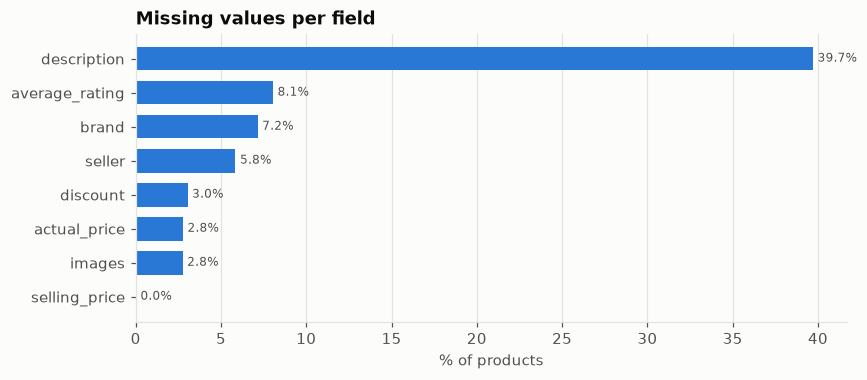

In [5]:
barh(missing_table["missing_%"][missing_table["missing"] > 0], "Missing values per field", "% of products",
     "missing_values", fmt="{:.1f}%")

### 1.2 Data-quality checks

Distinct values per field, duplicated titles, texts with encoding errors (mojibake) and `sub_category` values that do not look like generic sub-categories.

In [6]:
def hashable(v):
    """Make list / dict values hashable so that distinct values can be counted."""
    return json.dumps(v, sort_keys=True) if isinstance(v, (list, dict)) else v

text_cols = ["title", "description"]
quality = pd.Series({
    "documents": len(raw),
    "distinct titles": raw["title"].str.strip().nunique(),
    "documents whose title is shared with another document": int(raw["title"].str.strip().duplicated(keep=False).sum()),
    "distinct descriptions (non-empty)": raw.loc[raw["description"].str.strip() != "", "description"].nunique(),
    "texts with mojibake (title/description)": int(raw[text_cols].map(lambda t: fix_mojibake(t) != t).any(axis=1).sum()),
    "texts with non-ASCII characters": int(raw[text_cols].map(lambda t: not t.isascii()).any(axis=1).sum()),
}).to_frame("value")
display(quality)
display(pd.DataFrame({"distinct values": {c: raw[c].map(hashable).nunique() for c in OUTPUT_FIELDS}}).T)
print("sub_category values:")
raw["sub_category"].value_counts()

,value
documents,28080
distinct titles,5953
documents whose title is shared with another document,24462
distinct descriptions (non-empty),5683
texts with mojibake (title/description),92
texts with non-ASCII characters,7753


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
distinct values,28080,5953,5684,325,4,24,26855,535,2,1512,88,728,39,28080


sub_category values:


sub_category
Topwear                                 15310
Bottomwear                               3666
Winter Wear                              2493
Innerwear and Swimwear                   1762
Clothing Accessories                     1742
Kurtas, Ethnic Sets and Bottoms          1180
Men's Footwear                            920
Fabrics                                   534
Sleepwear                                 122
Blazers, Waistcoats and Suits             103
Tracksuits                                 90
Raincoats                                  34
Uber Urban Clothing and Accessories        28
Inspire Clothing and Accessories           23
Sunshopping Bags, Wallets & Belts          21
Crocks Club Clothing and Accessories       15
Roy Clothing and Accessories               12
SUNSHOPPING Bags, Wallets & Belts          10
Winsome Deal Bags, Wallets & Belts          4
INSPIRE Clothing and Accessories            4
YOFAMA Bags, Wallets & Belts                4
Party Supplies       

## 2. Text pre-processing (`title`, `description`)

`build_terms` (in `myapp/search/preprocessing.py`): mojibake repair → accent folding, other non-ASCII characters and
apostrophes to spaces → lower-casing → joining of single-letter compounds (`t-shirt`, `t shirt` → `tshirt`; `v-neck`,
`v neck` → `vneck`) → tokenization on every non-alphanumeric character (removes punctuation) → removal of purely
numeric tokens and tokens shorter than 2 characters → NLTK English stop-word removal → Porter stemming.
The cell below shows the output on a few examples.

In [7]:
examples = [raw.loc[0, "title"], raw.loc[0, "description"],
            "Typography Women V Neck Multicolor T-Shirt  (Pack of 2)",
            "Café crème Men's Slim-Fit Jeans",
            "Solid Men Round Neck T Shirt, Self Design V-Neck"]
MOJIBAKE = "â\u0080\u0099"   # a UTF-8 right quote decoded as Latin-1
examples += [t[t.index(MOJIBAKE) - 40:t.index(MOJIBAKE) + 40] for t in raw["description"] if MOJIBAKE in t][:1]
for text in examples:
    print("RAW:  ", repr(text))
    print("TERMS:", build_terms(text), "\n")

RAW:   'Solid Women Multicolor Track Pants'
TERMS: ['solid', 'women', 'multicolor', 'track', 'pant'] 

RAW:   'Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India'
TERMS: ['yorker', 'trackpant', 'made', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india'] 

RAW:   'Typography Women V Neck Multicolor T-Shirt  (Pack of 2)'
TERMS: ['typographi', 'women', 'vneck', 'multicolor', 'tshirt', 'pack'] 

RAW:   "Café crème Men's Slim-Fit Jeans"
TERMS: ['cafe', 'creme', 'men', 'slim', 'fit', 'jean'] 

RAW:   'Solid Men Round Neck T Shirt, Self Design V-Neck'
TERMS: ['solid', 'men', 'round', 'neck', 'tshirt', 'self', 'design', 'vneck'] 

RAW:   'shoes provide maximum return whether youâ\x80\x99re running between the wickets for 

Step-by-step view of the pipeline on one description.

In [8]:
text = raw.loc[0, "description"]
steps = {"normalized": normalize_text(text)}
steps["tokens"] = tokenize(steps["normalized"])
steps["no numbers / short"] = build_terms(text, remove_stopwords=False, stemmer=None)
steps["no stop words"] = build_terms(text, stemmer=None)
steps["stemmed (final)"] = build_terms(text)
for name, value in steps.items():
    print(f"{name:>19}: {value}")

         normalized: yorker trackpants made from 100% rich combed cotton giving it a rich look.designed for comfort,skin friendly fabric,itch-free waistband & great for all year round use proudly made in india
             tokens: ['yorker', 'trackpants', 'made', 'from', '100', 'rich', 'combed', 'cotton', 'giving', 'it', 'a', 'rich', 'look', 'designed', 'for', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'great', 'for', 'all', 'year', 'round', 'use', 'proudly', 'made', 'in', 'india']
 no numbers / short: ['yorker', 'trackpants', 'made', 'from', 'rich', 'combed', 'cotton', 'giving', 'it', 'rich', 'look', 'designed', 'for', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'great', 'for', 'all', 'year', 'round', 'use', 'proudly', 'made', 'in', 'india']
      no stop words: ['yorker', 'trackpants', 'made', 'rich', 'combed', 'cotton', 'giving', 'rich', 'look', 'designed', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'gre

### 2.1 Effect of each step on the vocabulary

Vocabulary size and number of terms of title + description under cumulative pipeline configurations (Snowball shown as an alternative stemmer).

In [9]:
configs = {
    "tokens only (stop words, numbers, 1-char tokens kept; no stemming)": dict(remove_stopwords=False, stemmer=None,
                                                                              keep_numbers=True, min_length=1),
    "+ stop words removed": dict(stemmer=None, keep_numbers=True, min_length=1),
    "+ numbers and 1-char tokens removed": dict(stemmer=None),
    "+ Porter stemming (default)": dict(stemmer="porter"),
    "Snowball stemming instead of Porter": dict(stemmer="snowball"),
}
text_per_doc = (raw["title"] + " " + raw["description"]).tolist()
rows = []
for name, opts in configs.items():
    counts = Counter(t for text in text_per_doc for t in build_terms(text, **opts))
    rows.append({"configuration (title + description)": name, "vocabulary": len(counts),
                 "total terms": sum(counts.values()), "avg terms / doc": round(sum(counts.values()) / len(text_per_doc), 1)})
pd.DataFrame(rows)

,configuration (title + description),vocabulary,total terms,avg terms / doc
0,"tokens only (stop words, numbers, 1-char tokens kept; no stemming)",6519,1030794,36.7
1,+ stop words removed,6391,704443,25.1
2,+ numbers and 1-char tokens removed,6203,687524,24.5
3,+ Porter stemming (default),4734,687524,24.5
4,Snowball stemming instead of Porter,4714,687524,24.5


## 3. Other text fields (`category`, `sub_category`, `brand`, `product_details`, `seller`)

Each field gets its own list of terms (`<field>_terms`, same `build_terms` pipeline) and `all_terms` concatenates the
fields listed in `merged_fields` (default: all text fields), so both a field-weighted and a single-field index can be
built from the same output.

### 3.1 `product_details`

Attribute names by frequency, with the number of distinct values and the most frequent value of each.

In [10]:
details_values = {}
for details in raw["product_details"]:
    for item in details:
        for key, value in item.items():
            details_values.setdefault(key.strip(), Counter())[value.strip()] += 1
details_keys = pd.DataFrame({
    "products": {k: sum(c.values()) for k, c in details_values.items()},
    "distinct values": {k: len(c) for k, c in details_values.items()},
    "most frequent value": {k: c.most_common(1)[0][0][:40] for k, c in details_values.items()},
}).sort_values("products", ascending=False)
print(f"{len(details_keys)} distinct attribute names (after stripping whitespace)")
details_keys.head(30)

126 distinct attribute names (after stripping whitespace)


,products,distinct values,most frequent value
Fabric,25959,244,Cotton Blend
Style Code,25763,23263,3
Pattern,25692,118,Solid
Fabric Care,21830,472,Gentle Machine Wash
Suitable For,19139,4,Western Wear
Sleeve,18861,21,Half Sleeve
Pack of,17953,13,1
Type,17394,156,Round Neck
Ideal For,16983,9,Women
Fit,16808,45,Regular


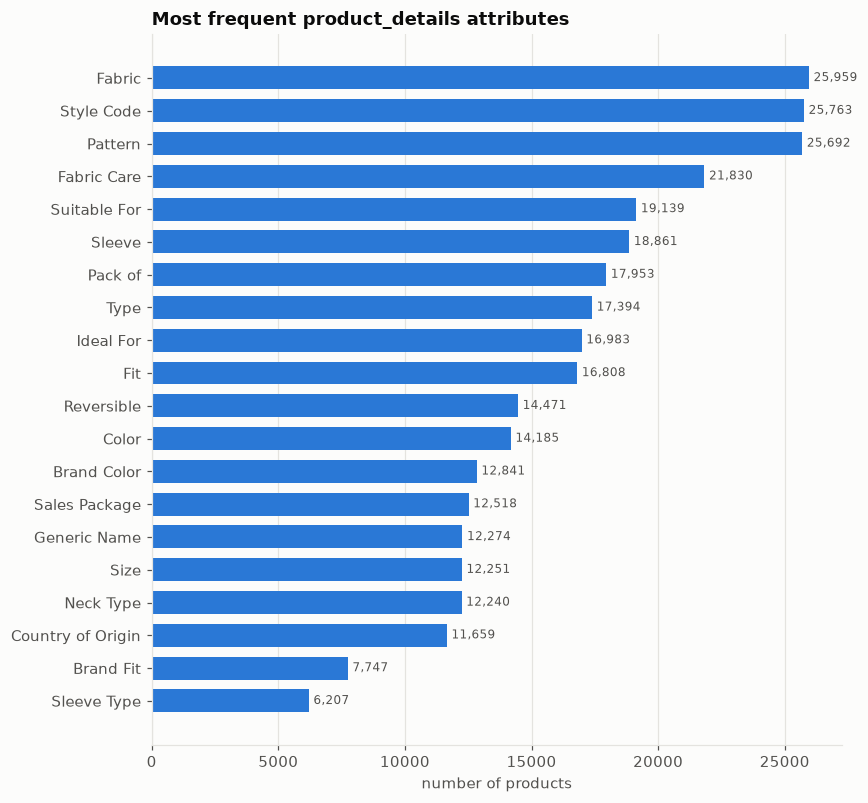

In [11]:
barh(details_keys["products"].head(20), "Most frequent product_details attributes", "number of products",
     "product_details_keys")

Parsed dict and the indexed terms for one product: `Style Code` is excluded, Yes/No attributes index the attribute name only when the value is Yes.

In [12]:
example = raw.loc[raw["product_details"].map(lambda d: any("Hooded" in i for i in d))].iloc[0]
parsed = parse_product_details(example["product_details"])
print("excluded keys:", DETAILS_EXCLUDED_KEYS)
print("parsed:", parsed)
print("terms: ", preprocess_corpus([example.to_dict()]).iloc[0]["product_details_terms"])

excluded keys: {'Style Code'}
parsed: {'Color': 'Multicolor', 'Fabric': 'Denim', 'Pattern': 'Washed', 'Style Code': 'XBFC-BKR-BOLT', 'Ideal For': 'Men', 'Sleeve': 'Full Sleeve', 'Character': 'None', 'Secondary Color': 'Multicolor', 'Closure': 'Zipper', 'Pack of': '1', 'Suitable For': 'Western Wear', 'Reversible': 'No', 'Hooded': 'No', 'Cuff': 'Button Cuff', 'Fabric Care': 'Gentle Machine Wash', 'Fit': 'Slim', 'Pockets': '4', 'Weave Type': 'Twill'}
terms:  ['multicolor', 'denim', 'wash', 'men', 'full', 'sleev', 'multicolor', 'zipper', 'western', 'wear', 'button', 'cuff', 'gentl', 'machin', 'wash', 'slim', 'twill']


### 3.2 `brand`: recovery of the full name from the URL

Compares the `brand` field with the brand recovered from the URL slug by `recover_brand` (used for `brand_terms`; the original `brand` is kept unchanged).

In [13]:
for i in raw.drop_duplicates("brand").index[:12]:
    print(f"{raw.loc[i, 'brand']!r:>24} -> {recover_brand(raw.loc[i, 'brand'], raw.loc[i, 'url'])!r:24} {raw.loc[i, 'url'][25:75]}")

                  'York' -> 'yorker'                 yorker-solid-men-multicolor-track-pants/p/itmd2c76
                  'ANGI' -> 'angira'                 angira-men-self-design-ankle-length/p/itm895dfea46
                      '' -> None                     nu-lite-satin-tie-cufflink/p/itmcaed1978977d4?pid=
                   'Man' -> 'manra'                  manra-striped-collared-neck-casual-men-green-sweat
            'TRANSPERAN' -> 'transperancy'           transperancy-solid-men-raincoat/p/itm9bf91ea64dd5a
         'DISCOUNT OUTL' -> 'discount outlet'        discount-outlet-self-design-men-polo-neck-black-t-
        'adidas Origina' -> 'adidas originals'       adidas-originals-sporty-men-round-neck-grey-t-shir
              'Fresh Fe' -> 'fresh feet'             fresh-feet-men-striped-ankle-length/p/itm0239301f9
               'SayItLo' -> 'sayitloud'              sayitloud-printed-men-boxer/p/itmb6483a1879b8e?pid
                'ShreeR' -> 'shreeram'               shreeram-re

In [14]:
has_brand = raw["brand"].str.strip() != ""
recovered = raw[has_brand].apply(lambda r: recover_brand(r["brand"], r["url"]), axis=1)
brand_tokens = raw.loc[recovered.dropna().index, "brand"].map(lambda b: " ".join(tokenize(normalize_text(b))))
forms = pd.DataFrame({"brand": raw.loc[recovered.dropna().index, "brand"], "recovered": recovered.dropna()})
ambiguous = forms.groupby("brand")["recovered"].nunique()
print(f"products with a brand: {has_brand.sum():,}")
print(f"brand recovered from URL: {recovered.notna().sum():,} ({recovered.notna().mean():.1%})")
print(f"recovered name longer than the brand field: {(recovered.dropna() != brand_tokens).sum():,}")
print(f"brand values recovered to more than one name: {(ambiguous > 1).sum()} -> "
      f"{forms[forms['brand'].isin(ambiguous[ambiguous > 1].index)].value_counts().to_dict()}")
print("\nnot recovered (most frequent):")
print(raw.loc[recovered[recovered.isna()].index, "brand"].value_counts().head(10).to_string())

products with a brand: 26,071
brand recovered from URL: 25,915 (99.4%)
recovered name longer than the brand field: 25,549
brand values recovered to more than one name: 5 -> {('V', 'vip'): 337, ('A', 'atm'): 180, ('U.S. POLO ASS', 'u s polo association'): 56, ('A', 'avr'): 20, ('U.S. POLO ASS', 'u s polo assn'): 20, ('U.S. Polo Ass', 'u s polo assn'): 7, ('V', 'vkv'): 6, ('C', 'csf'): 3, ('C', 'csz'): 1, ('U.S. Polo Ass', 'u s polo association'): 1}

not recovered (most frequent):
brand
A J STYL              91
AS Tre                44
Boan Boan             15
JUARI BE A GENTLEM     5
A to Z life sty        1


### 3.3 Process the whole corpus

Runs `preprocess_corpus` on all documents and shows the term lists of the first products.

In [15]:
docs = preprocess_corpus(raw_docs)
print(docs.shape)
docs[["pid", "title", "brand", "brand_full", "title_terms", "brand_terms", "category_terms", "sub_category_terms",
      "product_details_terms", "seller_terms"]].head()

(28080, 23)


,pid,title,brand,brand_full,title_terms,brand_terms,category_terms,sub_category_terms,product_details_terms,seller_terms
pid,,,,,,,,,,
TKPFCZ9EA7H5FYZH,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,York,yorker,"[solid, women, multicolor, track, pant]",[yorker],"[cloth, accessori]",[bottomwear],"[elast, side, pocket, cotton, blend, solid, multicolor]","[shyam, enterpris]"
TKPFCZ9EJZV2UVRZ,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,York,yorker,"[solid, men, blue, track, pant]",[yorker],"[cloth, accessori]",[bottomwear],"[drawstr, elast, side, pocket, cotton, blend, solid, blue]","[shyam, enterpris]"
TKPFCZ9EHFCY5Z4Y,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,York,yorker,"[solid, men, multicolor, track, pant]",[yorker],"[cloth, accessori]",[bottomwear],"[elast, side, pocket, cotton, blend, solid, multicolor]","[shyam, enterpris]"
TKPFCZ9ESZZ7YWEF,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,York,yorker,"[solid, women, multicolor, track, pant]",[yorker],"[cloth, accessori]",[bottomwear],"[elast, side, pocket, cotton, blend, solid, multicolor]","[shyam, enterpris]"
TKPFCZ9EVXKBSUD7,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants",York,yorker,"[solid, women, brown, grey, track, pant]",[yorker],"[cloth, accessori]",[bottomwear],"[drawstr, elast, side, pocket, cotton, blend, solid, brown, grey]","[shyam, enterpris]"


Output fields: checks that every required field is kept, that `pid` is unchanged, the types of the parsed fields, and that every processed document validates against the template's `Document` model (`myapp/search/objects.py`).

In [16]:
assert list(docs.columns[:len(OUTPUT_FIELDS)]) == OUTPUT_FIELDS
assert (docs["pid"].values == raw["pid"].values).all()
for record in docs[OUTPUT_FIELDS].to_dict("records"):
    Document(**{k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in record.items()})
print("all", len(docs), "documents validate against myapp.search.objects.Document")
display(docs[OUTPUT_FIELDS].dtypes.to_frame("dtype").T)
docs[OUTPUT_FIELDS].head(3)

all 28080 documents validate against myapp.search.objects.Document


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
dtype,object,object,object,object,object,object,object,object,bool,float64,float64,float64,float64,object


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
pid,,,,,,,,,,,,,,
TKPFCZ9EA7H5FYZH,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,York,Clothing and Accessories,Bottomwear,"{'Style Code': '1005COMBO2', 'Closure': 'Elastic', 'Pockets': 'Side Pockets'...",Shyam Enterprises,False,921.0,69.0,2999.0,3.9,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76a...
TKPFCZ9EJZV2UVRZ,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,York,Clothing and Accessories,Bottomwear,"{'Style Code': '1005BLUE', 'Closure': 'Drawstring, Elastic', 'Pockets': 'Sid...",Shyam Enterprises,False,499.0,66.0,1499.0,3.9,https://www.flipkart.com/yorker-solid-men-blue-track-pants/p/itmfczez7v6rzwe...
TKPFCZ9EHFCY5Z4Y,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,York,Clothing and Accessories,Bottomwear,"{'Style Code': '1005COMBO4', 'Closure': 'Elastic', 'Pockets': 'Side Pockets'...",Shyam Enterprises,False,931.0,68.0,2999.0,3.9,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itm1eee3c...


### 3.4 Save the processed corpus

Saves the full processed corpus to `data/processed_corpus.jsonl` (reloaded in later parts with `load_processed_corpus`) and a 20-document sample to `output/processed_documents_sample.json`, then checks the round trip.

In [17]:
save_processed_corpus(docs, PROCESSED_PATH)
docs.head(20).to_json(OUT_DIR / "processed_documents_sample.json", orient="records", indent=2, force_ascii=False)
reloaded = load_processed_corpus(PROCESSED_PATH)
assert reloaded.shape == docs.shape and (reloaded["all_terms"].map(len) == docs["all_terms"].map(len)).all()
print("saved", PROCESSED_PATH.relative_to(REPO_ROOT), f"({PROCESSED_PATH.stat().st_size / 2**20:.1f} MiB)")
print("saved", (OUT_DIR / "processed_documents_sample.json").relative_to(REPO_ROOT))

saved data/processed_corpus.jsonl (58.5 MiB)
saved project_progress/part_1/output/processed_documents_sample.json


## 4. Numeric and boolean fields (`out_of_stock`, `selling_price`, `discount`, `actual_price`, `average_rating`)

These fields are parsed into numbers / booleans (`"2,999"` → 2999.0, `"69% off"` → 69.0, `"3.9"` → 3.9, missing → null)
and are not turned into terms. The cells show the parsed values and a consistency check of `discount` against the two prices.

In [18]:
display(pd.DataFrame({"raw example": raw.loc[0, NUMERIC_FIELDS], "parsed": docs.iloc[0][NUMERIC_FIELDS]}))
docs[NUMERIC_FIELDS].describe().round(2)

,raw example,parsed
out_of_stock,False,False
selling_price,921,921.0
discount,69% off,69.0
actual_price,"2,999",2999.0
average_rating,3.9,3.9


,selling_price,discount,actual_price,average_rating
count,28078.00,27225.00,27303.00,25819.00
mean,705.64,50.26,1455.53,3.63
std,549.68,16.89,939.98,0.66
min,99.00,1.00,150.00,1.00
25%,390.00,40.00,849.00,3.20
50%,545.00,53.00,1199.00,3.80
75%,820.00,63.00,1799.00,4.10
max,7999.00,87.00,12999.00,5.00


In [19]:
# discount recomputed from the two prices vs the stated discount
computed = 100 * (1 - docs["selling_price"] / docs["actual_price"])
both = docs["discount"].notna() & computed.notna()
diff = (computed[both] - docs.loc[both, "discount"]).abs()
print(f"documents with discount and both prices: {both.sum():,}")
print(f"|computed - stated| < 1 point: {(diff < 1).sum():,}; >= 1 point: {(diff >= 1).sum()} (max difference {diff.max():.2f})")
display(docs.loc[diff[diff >= 1].index, ["title", "selling_price", "actual_price", "discount"]])
print(f"discount missing but both prices present: {(docs['discount'].isna() & computed.notna()).sum()} "
      f"(computed discount there: max {computed[docs['discount'].isna()].max():.2f}%)")
print(f"selling_price > actual_price: {(docs['selling_price'] > docs['actual_price']).sum()}")
print(f"distinct values: " + ", ".join(f"{c} {docs[c].nunique():,}" for c in NUMERIC_FIELDS))

documents with discount and both prices: 27,225
|computed - stated| < 1 point: 27,218; >= 1 point: 7 (max difference 45.00)


,title,selling_price,actual_price,discount
pid,,,,
CRGFUZ6FZUVNXQR7,Women Cargos,672.0,1600.0,57.0
SWSFJY5ZWGJPE59Z,Full Sleeve Solid Women Sweatshirt,2599.0,2599.0,40.0
TSHFFXV2UQBFFRZZ,Printed Men Round Neck Yellow T-Shirt,430.0,1000.0,56.0
TSHFGF73GJHQHF9S,Graphic Print Men Round Neck Yellow T-Shirt,430.0,1000.0,56.0
TSHFGF3M532SUK3U,Printed Men Round Neck Grey T-Shirt,430.0,1000.0,56.0
SWSFRAKJGJ4HDTDG,Full Sleeve Color Block Men Sweatshirt,4499.0,4499.0,45.0
JCKFUFGPKH4CCYBT,Full Sleeve Printed Men Sweatshirt,3499.0,3499.0,45.0


discount missing but both prices present: 78 (computed discount there: max 0.94%)
selling_price > actual_price: 0
distinct values: out_of_stock 2, selling_price 1,511, discount 87, actual_price 727, average_rating 38


## 5. Validation labels

Loads `validation_labels.csv` and joins the processed documents (by `pid`); the queries go through `preprocess_query`, the same pipeline as the documents.

In [20]:
labels = pd.read_csv(LABELS_PATH, dtype={"pid": str})
QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
print(labels.groupby(["query_id", "labels"]).size().unstack(fill_value=0))
assert labels["pid"].isin(docs.index).all(), "unknown pid in validation labels"
labelled = labels.join(docs.drop(columns=["title", "pid"]), on="pid")
QUERY_TERMS = {qid: preprocess_query(q) for qid, q in QUERIES.items()}
for qid, terms in QUERY_TERMS.items():
    print(f"query {qid}: {QUERIES[qid]!r} -> {terms}")

labels     0   1
query_id        
1          7  13
2         10  10
query 1: 'women full sleeve sweatshirt cotton' -> ['women', 'full', 'sleev', 'sweatshirt', 'cotton']
query 2: 'men slim jeans blue' -> ['men', 'slim', 'jean', 'blue']


Mean number of query terms found in each field, for relevant (1) and non-relevant (0) documents.

In [21]:
TERM_FIELDS = [f"{f}_terms" for f in TEXT_FIELDS] + ["all_terms"]
rows = []
for qid, q_terms in QUERY_TERMS.items():
    for _, row in labelled[labelled["query_id"] == qid].iterrows():
        for field in TERM_FIELDS:
            present = set(row[field])
            for term in q_terms:
                rows.append({"query_id": qid, "pid": row["pid"], "label": row["labels"],
                             "field": field.removesuffix("_terms"), "term": term, "present": term in present})
coverage = pd.DataFrame(rows)
matched = (coverage.groupby(["query_id", "field", "label", "pid"])["present"].sum()
           .groupby(["query_id", "field", "label"]).mean().unstack("label").round(2))
matched.columns = ["non-relevant (0)", "relevant (1)"]
matched["difference"] = matched["relevant (1)"] - matched["non-relevant (0)"]
matched

non-relevant (0)  relevant (1)  difference
query_id field                                                      
1        all                          5.00          5.00        0.00
         brand                        0.00          0.00        0.00
         category                     0.00          0.00        0.00
         description                  3.14          2.92       -0.22
         product_details              3.00          4.00        1.00
         seller                       0.00          0.00        0.00
         sub_category                 0.00          0.00        0.00
         title                        2.29          4.00        1.71
2        all                          3.20          3.60        0.40
         brand                        0.00          0.00        0.00
         category                     0.00          0.00        0.00
         description                  1.60          1.40       -0.20
         product_details              1.90          2.60        0.70
         seller                       0.00          0.00        0.00
         sub_category                 0.00          0.00        0.00
         title                        2.90          3.20        0.30

Share of labelled documents whose field contains each query term, by label.

In [22]:
for qid in QUERIES:
    print(f"\nquery {qid}: {QUERIES[qid]}")
    display(coverage[coverage["query_id"] == qid]
            .pivot_table(index=["field", "label"], columns="term", values="present", aggfunc="mean").round(2))


query 1: women full sleeve sweatshirt cotton


term                   cotton  full  sleev  sweatshirt  women
field           label                                        
all             0        1.00  1.00   1.00        1.00   1.00
                1        1.00  1.00   1.00        1.00   1.00
brand           0        0.00  0.00   0.00        0.00   0.00
                1        0.00  0.00   0.00        0.00   0.00
category        0        0.00  0.00   0.00        0.00   0.00
                1        0.00  0.00   0.00        0.00   0.00
description     0        1.00  0.57   0.71        0.57   0.29
                1        0.92  0.46   0.38        0.69   0.46
product_details 0        0.86  0.43   1.00        0.14   0.57
                1        0.85  1.00   1.00        0.85   0.31
seller          0        0.00  0.00   0.00        0.00   0.00
                1        0.00  0.00   0.00        0.00   0.00
sub_category    0        0.00  0.00   0.00        0.00   0.00
                1        0.00  0.00   0.00        0.00   0.00
title           0        0.00  0.43   0.43        0.43   1.00
                1        0.00  1.00   1.00        1.00   1.00


query 2: men slim jeans blue


term                   blue  jean  men  slim
field           label                       
all             0       1.0   1.0  0.2   1.0
                1       1.0   1.0  0.7   0.9
brand           0       0.0   0.0  0.0   0.0
                1       0.0   0.0  0.0   0.0
category        0       0.0   0.0  0.0   0.0
                1       0.0   0.0  0.0   0.0
description     0       0.5   0.7  0.0   0.4
                1       0.3   0.6  0.0   0.5
product_details 0       1.0   0.7  0.2   0.0
                1       1.0   0.9  0.7   0.0
seller          0       0.0   0.0  0.0   0.0
                1       0.0   0.0  0.0   0.0
sub_category    0       0.0   0.0  0.0   0.0
                1       0.0   0.0  0.0   0.0
title           0       1.0   1.0  0.2   0.7
                1       1.0   1.0  0.7   0.5

Numeric fields by label, and the main attributes of every labelled document.

In [23]:
display(labelled.groupby(["query_id", "labels"])[NUMERIC_FIELDS].mean().round(2))
cols = ["query_id", "labels", "title", "brand_full", "sub_category", "selling_price", "discount", "average_rating", "out_of_stock"]
labelled.assign(fabric=labelled["product_details"].map(lambda d: d.get("Fabric")),
                fit=labelled["product_details"].map(lambda d: d.get("Fit")),
                ideal_for=labelled["product_details"].map(lambda d: d.get("Ideal For")))[cols + ["fabric", "fit", "ideal_for"]]

out_of_stock  selling_price  discount  actual_price  average_rating
query_id labels                                                                     
1        0               0.00        1392.86     45.71       2541.86            3.94
         1               0.15        1143.08     52.23       2312.92            3.77
2        0               0.20        1959.50     33.20       2899.00            3.36
         1               0.10        1999.60     24.67       2039.00            2.89

,query_id,labels,title,brand_full,sub_category,selling_price,discount,average_rating,out_of_stock,fabric,fit,ideal_for
0,1,1,Full Sleeve Printed Women Sweatshirt,cupidstore,Winter Wear,999.0,41.0,3.2,False,Cotton Blend,None,None
1,1,0,Full Sleeve Striped Women Sweatshirt,reebok,Winter Wear,2441.0,35.0,4.0,False,Polyester Blend,None,None
2,1,1,Full Sleeve Printed Women Sweatshirt,puma,Winter Wear,2099.0,40.0,4.3,False,Cotton Blend,None,None
3,1,1,Full Sleeve Graphic Print Women Sweatshirt,free authority,Winter Wear,949.0,50.0,3.9,False,Polycotton,None,None
4,1,0,Full Sleeve Solid Women Sweatshirt,puma,Winter Wear,2249.0,50.0,3.7,False,Cotton Blend,None,None
5,1,1,Full Sleeve Graphic Print Women Sweatshirt,free authority,Winter Wear,899.0,50.0,3.9,False,Polycotton,None,None
6,1,0,Typography Women V Neck Multicolor T-Shirt (Pack of 2),free authority,Topwear,824.0,45.0,3.9,False,Pure Cotton,Regular,Women
7,1,1,Full Sleeve Printed Women Sweatshirt,puma,Winter Wear,2699.0,40.0,4.2,False,Cotton Blend,None,None
8,1,1,Full Sleeve Solid Women Sweatshirt,reebok,Winter Wear,2313.0,35.0,3.9,False,Cotton Blend,None,None
9,1,1,Full Sleeve Graphic Print Women Sweatshirt,free authority,Winter Wear,849.0,50.0,3.9,False,Polycotton,None,None


## 6. Exploratory data analysis

### 6.1 Word counts

Words per title and description before pre-processing (tokens of the normalized text) and terms after pre-processing; descriptions are also summarised without the empty ones.

In [24]:
has_desc = docs["description"].notna().values
lengths = pd.DataFrame({
    "title_words": raw["title"].map(lambda t: len(tokenize(normalize_text(t)))).values,
    "description_words": raw["description"].map(lambda t: len(tokenize(normalize_text(t)))).values,
    "title_terms": docs["title_terms"].map(len).values,
    "description_terms": docs["description_terms"].map(len).values,
    "product_details_terms": docs["product_details_terms"].map(len).values,
    "all_terms": docs["all_terms"].map(len).values,
}, index=docs.index)
summary = lengths.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(1)
summary["description_words (non-empty)"] = lengths.loc[has_desc, "description_words"].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(1)
summary

,title_words,description_words,title_terms,description_terms,product_details_terms,all_terms,description_words (non-empty)
count,28080.0,28080.0,28080.0,28080.0,28080.0,28080.0,16930.0
mean,6.5,30.2,6.1,18.4,20.6,51.1,50.1
std,2.2,45.1,1.8,26.1,10.7,31.1,48.8
min,1.0,0.0,1.0,0.0,0.0,10.0,1.0
25%,6.0,0.0,5.0,0.0,14.0,30.0,14.0
50%,6.0,11.0,6.0,9.0,19.0,41.0,39.0
75%,7.0,49.0,7.0,28.0,25.0,64.0,65.0
99%,13.0,207.0,11.0,104.0,54.0,150.0,207.0
max,36.0,617.0,27.0,543.0,145.0,581.0,617.0


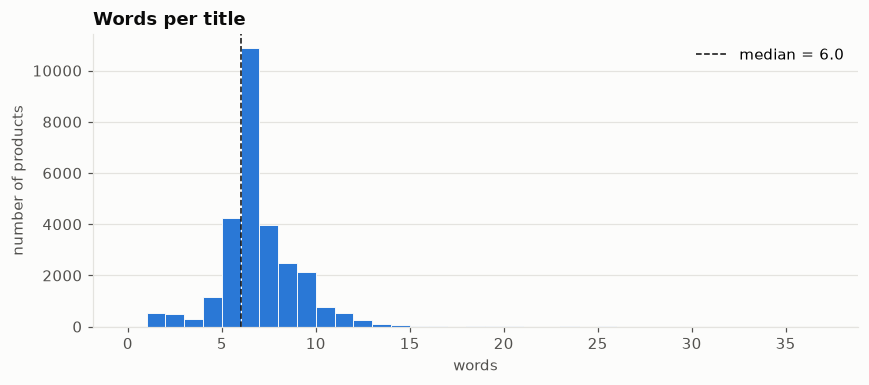

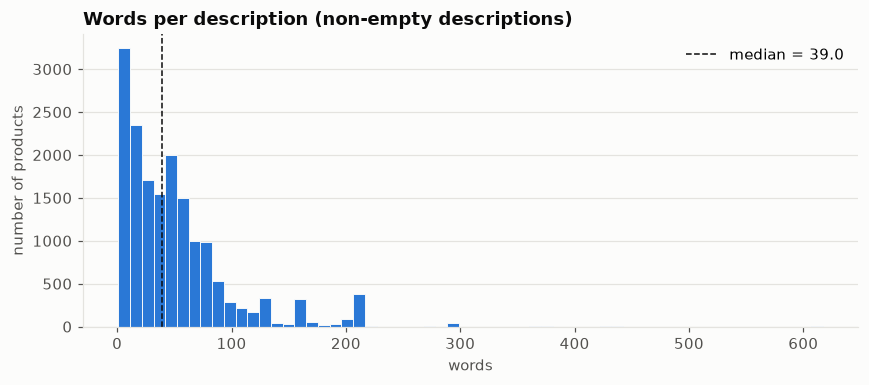

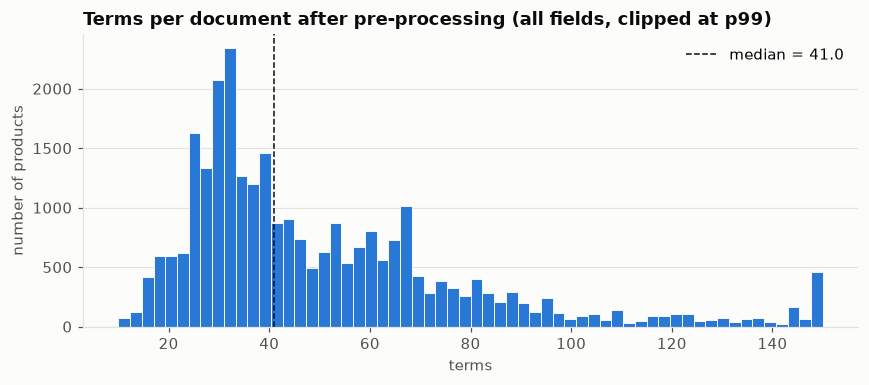

In [25]:
hist(lengths["title_words"], "Words per title", "words", "title_word_count", bins=range(0, lengths["title_words"].max() + 2))
hist(lengths.loc[has_desc, "description_words"], "Words per description (non-empty descriptions)", "words",
     "description_word_count", bins=60)
hist(lengths["all_terms"].clip(upper=lengths["all_terms"].quantile(0.99)), "Terms per document after pre-processing (all fields, clipped at p99)",
     "terms", "all_terms_count", bins=60)

### 6.2 Sentence length

Splits descriptions into sentences on `.`, `!`, `?` followed by whitespace or directly by an uppercase letter (descriptions often lack the space after a full stop; decimals such as 2.5 are not split) and counts words per sentence.

descriptions: 16,930  sentences: 54,518
average sentence length: 15.57 words (median 14)
average sentences per description: 3.22 (median 2)


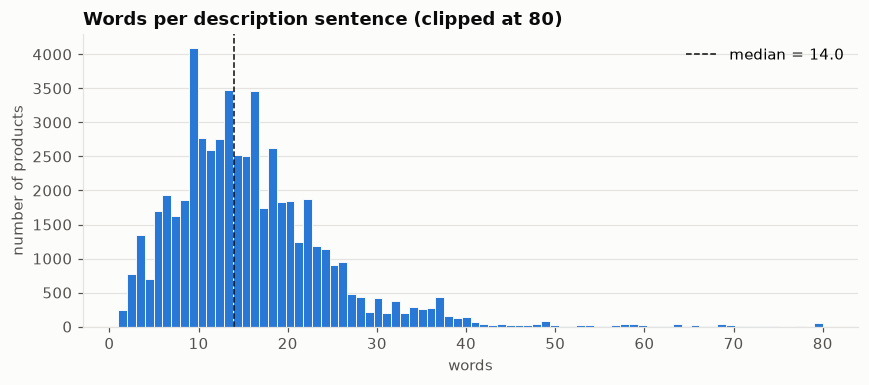

In [26]:
SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+|(?<=[a-z][.!?])(?=[A-Z])")


def sentences(text):
    """Split a text into sentences, dropping pieces without any word."""
    return [s for s in SENTENCE_SPLIT.split(fix_mojibake(text).strip()) if tokenize(normalize_text(s))]


desc = raw.loc[has_desc, "description"]
sentence_lengths = pd.Series([len(tokenize(normalize_text(s))) for d in desc for s in sentences(d)])
sentences_per_desc = desc.map(lambda d: len(sentences(d)))
print(f"descriptions: {len(desc):,}  sentences: {len(sentence_lengths):,}")
print(f"average sentence length: {sentence_lengths.mean():.2f} words (median {sentence_lengths.median():.0f})")
print(f"average sentences per description: {sentences_per_desc.mean():.2f} (median {sentences_per_desc.median():.0f})")
hist(sentence_lengths.clip(upper=80), "Words per description sentence (clipped at 80)", "words", "sentence_length", bins=80)

### 6.3 Vocabulary

Vocabulary size, total terms and hapax legomena per field (stemmed terms).

In [27]:
def vocabulary(series):
    """Term frequencies over a Series of term lists."""
    return Counter(t for terms in series for t in terms)

vocab_rows = []
for field in TEXT_FIELDS + ["title + description", "all"]:
    if field == "title + description":
        counts = vocabulary(docs["title_terms"] + docs["description_terms"])
    else:
        counts = vocabulary(docs["all_terms" if field == "all" else f"{field}_terms"])
    vocab_rows.append({"field": field, "vocabulary size": len(counts), "total terms": sum(counts.values()),
                       "terms / doc": round(sum(counts.values()) / len(docs), 2),
                       "hapax (freq = 1)": sum(1 for c in counts.values() if c == 1)})
pd.DataFrame(vocab_rows).set_index("field")

,vocabulary size,total terms,terms / doc,hapax (freq = 1)
field,,,,
title,651,170212,6.06,182
description,4574,517314,18.42,948
brand,415,36703,1.31,45
category,7,55280,1.97,1
sub_category,39,39079,1.39,5
product_details,3470,577237,20.56,1164
seller,672,40382,1.44,138
title + description,4735,687526,24.48,998
all,6822,1436207,51.15,1781


Most frequent terms (all fields and titles only) and most frequent title bigrams.

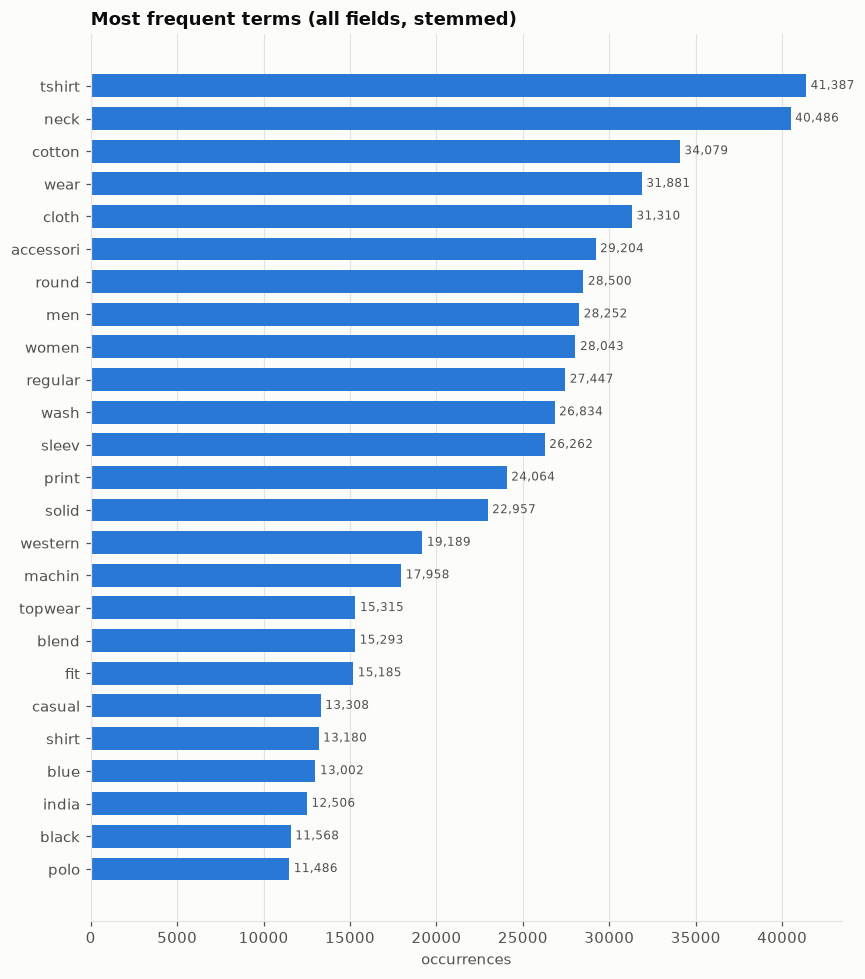

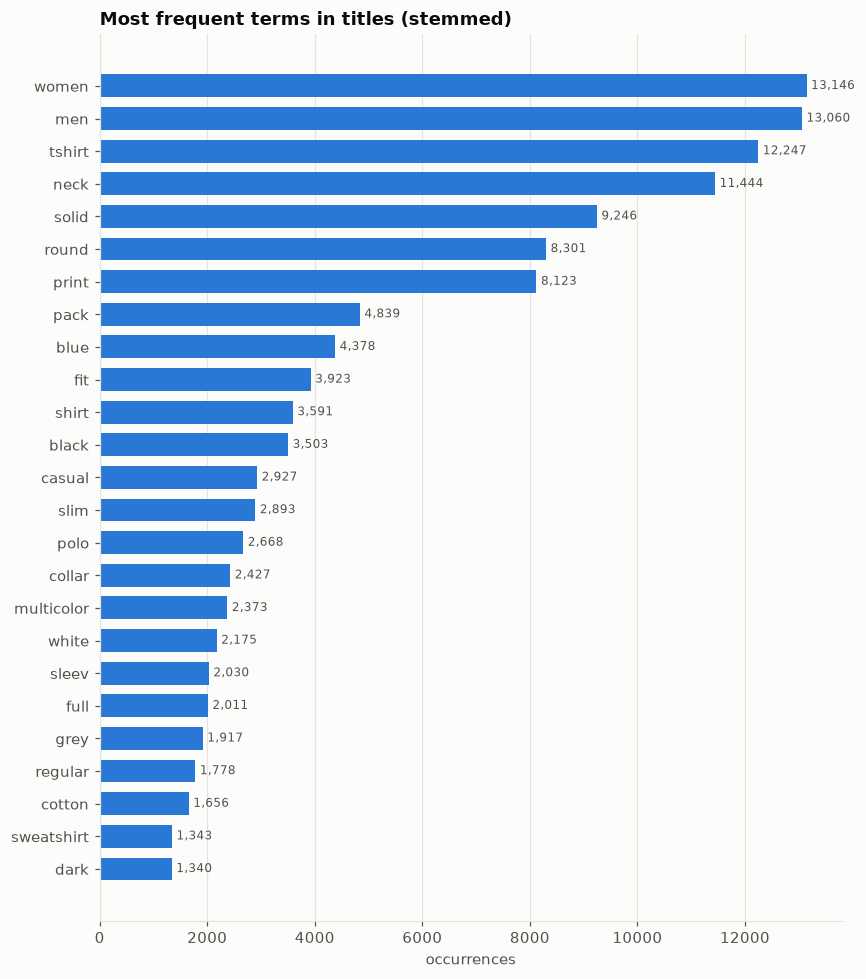

,title bigram,occurrences
0,round neck,8049
1,men round,4135
2,women round,4082
3,solid men,3534
4,solid women,3503
5,print men,3272
6,print women,3232
7,polo neck,2668
8,casual shirt,2527
9,slim fit,2350


In [28]:
barh(pd.Series(dict(vocabulary(docs["all_terms"]).most_common(25))), "Most frequent terms (all fields, stemmed)",
     "occurrences", "top_terms_all")
barh(pd.Series(dict(vocabulary(docs["title_terms"]).most_common(25))), "Most frequent terms in titles (stemmed)",
     "occurrences", "top_terms_title")
bigrams = Counter(b for terms in docs["title_terms"] for b in zip(terms, terms[1:]))
pd.DataFrame([(" ".join(b), n) for b, n in bigrams.most_common(15)], columns=["title bigram", "occurrences"])

Zipf (rank-frequency, log-log) and Heaps (vocabulary growth) plots of title + description terms, with a least-squares fit of Heaps' law V = K·nᵝ.

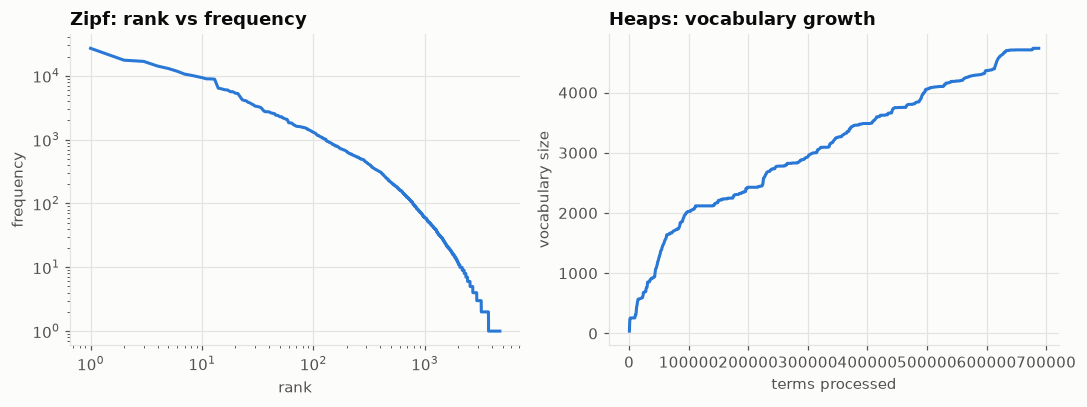

Heaps fit: K = 3.00, beta = 0.549


In [29]:
td_terms = [t for a, b in zip(docs["title_terms"], docs["description_terms"]) for t in a + b]
freqs = np.array(sorted(Counter(td_terms).values(), reverse=True))
seen, growth = set(), []
for i, t in enumerate(td_terms, 1):
    seen.add(t)
    if i % 500 == 0:
        growth.append((i, len(seen)))
growth = np.array(growth)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.loglog(np.arange(1, len(freqs) + 1), freqs, color=BLUE, linewidth=2)
ax1.set_title("Zipf: rank vs frequency")
ax1.set_xlabel("rank")
ax1.set_ylabel("frequency")
ax2.plot(growth[:, 0], growth[:, 1], color=BLUE, linewidth=2)
ax2.set_title("Heaps: vocabulary growth")
ax2.set_xlabel("terms processed")
ax2.set_ylabel("vocabulary size")
savefig(fig, "zipf_heaps")
plt.show()

beta, log_k = np.polyfit(np.log(growth[:, 0]), np.log(growth[:, 1]), 1)
print(f"Heaps fit: K = {np.exp(log_k):.2f}, beta = {beta:.3f}")

### 6.4 Word clouds

Word clouds of titles, descriptions and `product_details` values, built from unstemmed terms (stop words removed, otherwise the same pipeline) so that the words stay readable.

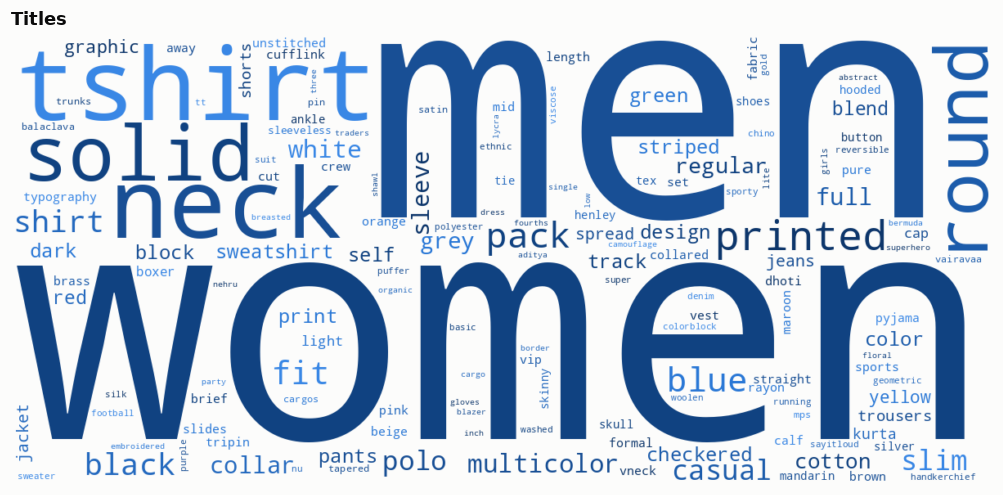

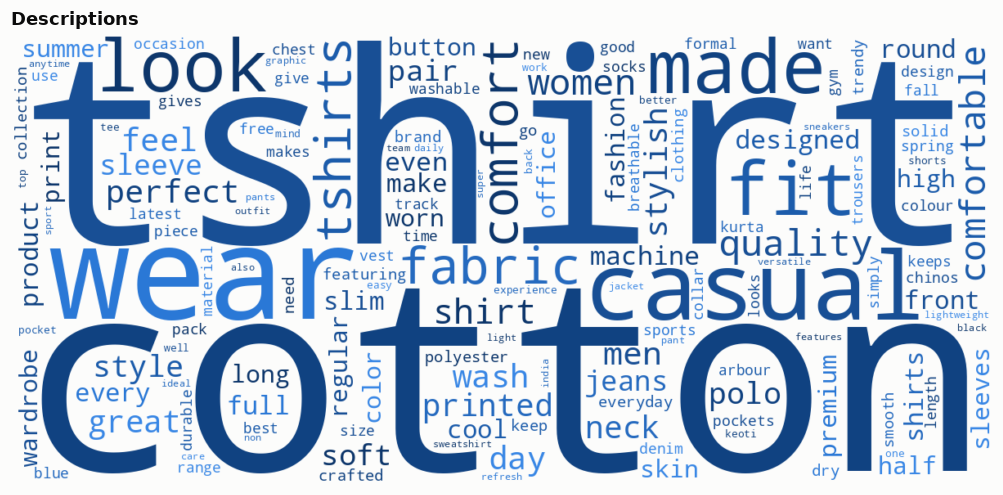

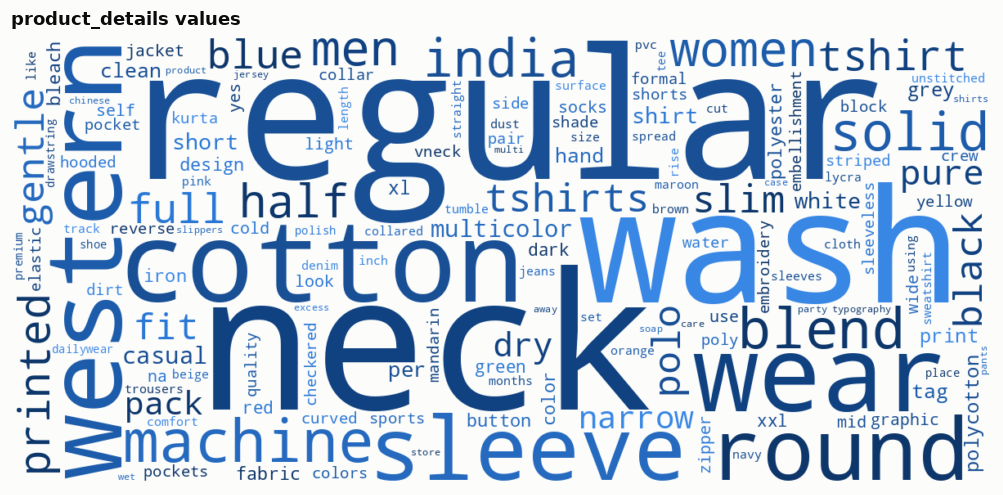

In [30]:
from wordcloud import WordCloud

CLOUD_COLORS = ["#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]


def blue_color(word, font_size, position, orientation, random_state=None, **kwargs):
    """Colour function for WordCloud: a random shade of blue."""
    return CLOUD_COLORS[random_state.randint(0, len(CLOUD_COLORS) - 1)]


def word_cloud(texts, title, name):
    """Draw and save a word cloud of the unstemmed terms of a collection of texts."""
    counts = Counter(t for text in texts for t in build_terms(text, stemmer=None))
    wc = WordCloud(width=1200, height=550, background_color="#fcfcfb", color_func=blue_color, random_state=RANDOM_STATE,
                   max_words=150, collocations=False, margin=6).generate_from_frequencies(counts)
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(title)
    savefig(fig, name)
    plt.show()


word_cloud(raw["title"], "Titles", "wordcloud_title")
word_cloud(raw["description"], "Descriptions", "wordcloud_description")
word_cloud(docs["product_details"].map(lambda d: " ".join(v for k, v in d.items() if k not in DETAILS_EXCLUDED_KEYS)),
           "product_details values", "wordcloud_product_details")

### 6.5 Categories and sub-categories

,products,share_%
category,,
Clothing and Accessories,27118,96.57
Footwear,920,3.28
"Bags, Wallets & Belts",41,0.15
Toys,1,0.00


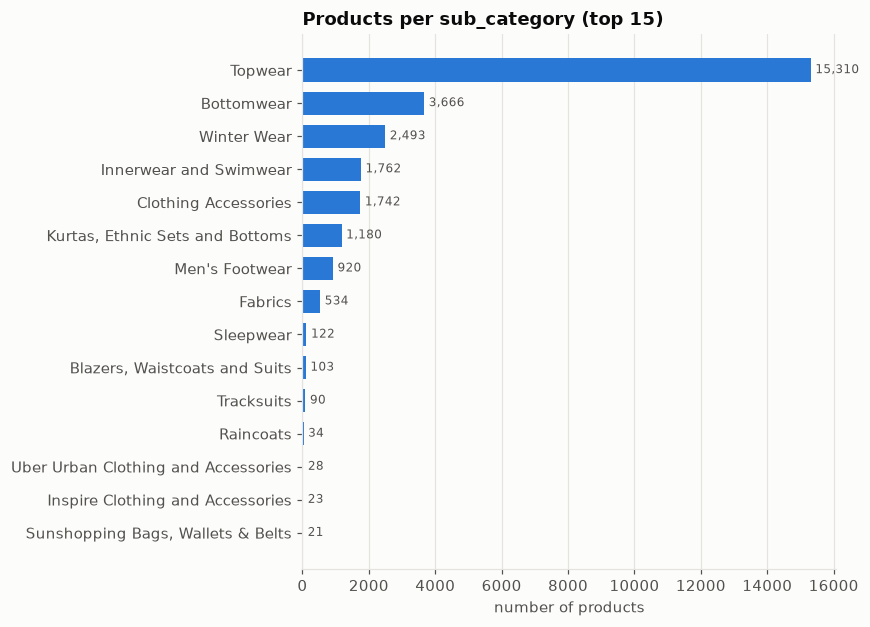

distinct sub_categories: 24


In [31]:
cat = docs["category"].value_counts()
display(pd.DataFrame({"products": cat, "share_%": (100 * cat / len(docs)).round(2)}))
barh(docs["sub_category"].value_counts().head(15), "Products per sub_category (top 15)", "number of products",
     "sub_category_counts")
print("distinct sub_categories:", docs["sub_category"].nunique())

### 6.6 Brands and sellers

Number of distinct brands and sellers, top 20 by number of products (brands by recovered name), with mean rating, median price and out-of-stock rate.

distinct brands (field): 324  distinct brands (recovered): 323  distinct sellers: 534


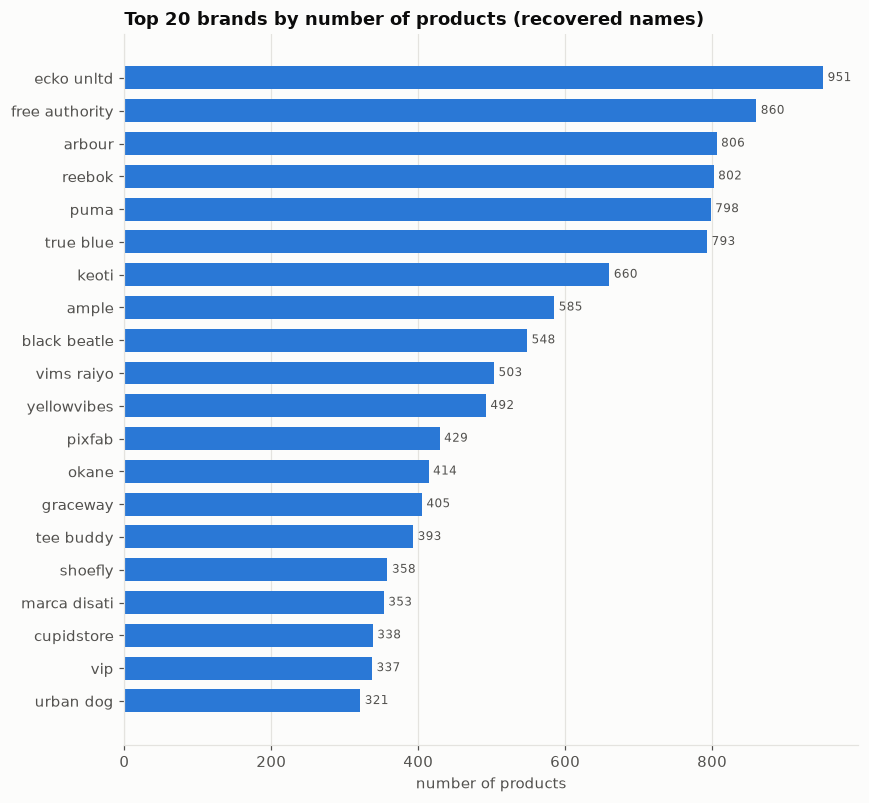

,products,mean_rating,median_price,out_of_stock_pct
brand_full,,,,
ecko unltd,951,2.71,769.0,6.73
free authority,860,3.91,519.0,3.49
arbour,806,4.10,417.0,2.85
reebok,802,4.01,1178.0,8.35
puma,798,4.06,1349.0,12.53
true blue,793,3.46,999.0,3.28
keoti,660,3.82,331.0,0.00
ample,585,3.41,525.0,0.00
black beatle,548,3.90,308.0,0.00


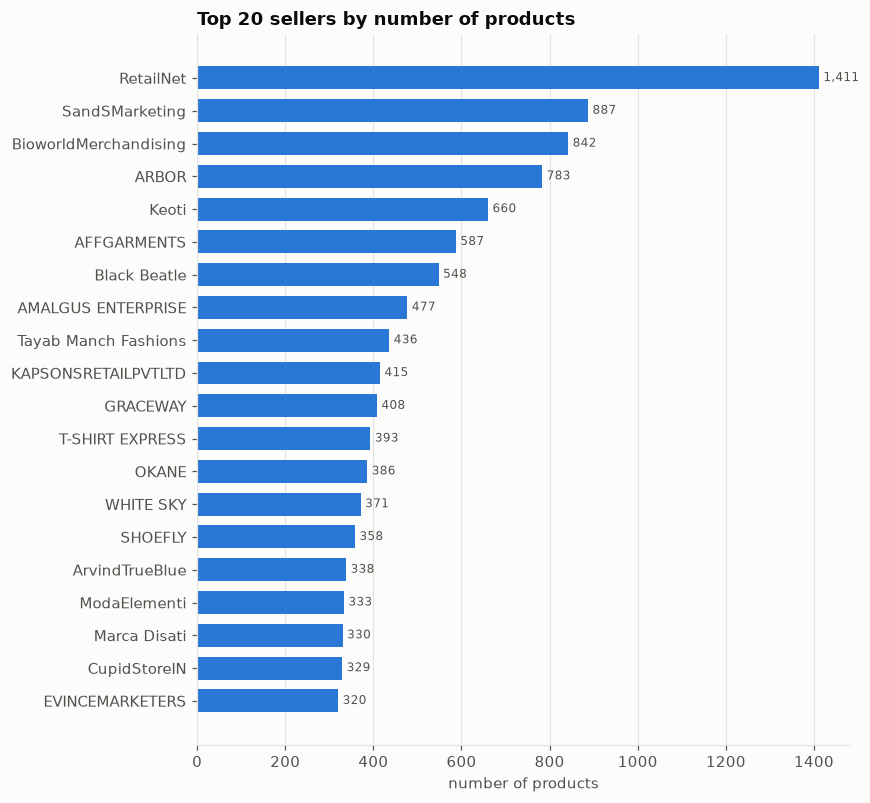

,products,mean_rating,median_price,out_of_stock_pct
seller,,,,
RetailNet,1411,4.11,1259.0,0.07
SandSMarketing,887,2.68,769.0,0.00
BioworldMerchandising,842,3.91,519.0,0.00
ARBOR,783,4.10,417.0,0.00
Keoti,660,3.82,331.0,0.00
AFFGARMENTS,587,3.41,525.0,0.00
Black Beatle,548,3.90,308.0,0.00
AMALGUS ENTERPRISE,477,3.32,785.0,0.00
Tayab Manch Fashions,436,3.96,1169.0,0.00


In [32]:
print("distinct brands (field):", docs["brand"].nunique(), " distinct brands (recovered):", docs["brand_full"].nunique(),
      " distinct sellers:", docs["seller"].nunique())


def group_stats(col, top=20):
    """Products, mean rating, median selling price and out-of-stock rate of the `top` largest groups of `col`."""
    g = docs.groupby(col).agg(products=("pid", "size"), mean_rating=("average_rating", "mean"),
                              median_price=("selling_price", "median"), out_of_stock_pct=("out_of_stock", "mean"))
    g["out_of_stock_pct"] *= 100
    return g.sort_values("products", ascending=False).head(top).round(2)


brand_stats, seller_stats = group_stats("brand_full"), group_stats("seller")
barh(brand_stats["products"], "Top 20 brands by number of products (recovered names)", "number of products", "top_brands")
display(brand_stats)
barh(seller_stats["products"], "Top 20 sellers by number of products", "number of products", "top_sellers")
display(seller_stats)

Brands and sellers with at least 50 rated products, ranked by mean rating; and concentration of products among them.

In [33]:
def rating_ranking(col, min_rated=50, top=15):
    """Groups of `col` with at least `min_rated` rated products, sorted by mean rating."""
    g = docs.groupby(col).agg(products=("pid", "size"), rated=("average_rating", "count"),
                              mean_rating=("average_rating", "mean"), mean_price=("selling_price", "mean"),
                              mean_discount=("discount", "mean"))
    return g[g["rated"] >= min_rated].sort_values("mean_rating", ascending=False).head(top).round(2)


display(rating_ranking("brand_full"))
display(rating_ranking("seller"))
for col, name in [("brand_full", "brand"), ("seller", "seller")]:
    vc = docs[col].value_counts()
    print(f"{name}: top 10 cover {100 * vc.head(10).sum() / vc.sum():.1f}% of products with a {name}; "
          f"{(vc == 1).sum()} {name}s have a single product")

,products,rated,mean_rating,mean_price,mean_discount
brand_full,,,,,
sorang,74,74,4.61,694.19,61.50
pixfab,429,328,4.46,305.03,76.03
cotson,277,277,4.44,356.88,39.19
zack ford,128,128,4.33,571.20,62.27
u s polo assn,50,50,4.32,1555.80,41.96
oneiro,57,57,4.23,520.74,62.67
graceway,405,404,4.23,412.07,58.46
marca disati,353,334,4.19,582.79,43.60
reebok classics,75,75,4.14,1723.51,44.85


,products,rated,mean_rating,mean_price,mean_discount
seller,,,,,
SORANG,74,74,4.61,694.19,61.50
EVINCEMARKETERS,320,320,4.48,357.75,38.84
PixFab,309,309,4.46,303.81,76.04
KrishnamEnterprisaes,128,128,4.33,571.20,62.27
GRACEWAY,408,408,4.23,415.41,58.19
Marca Disati,330,330,4.20,581.61,43.36
VAIRAVAA TEX,138,138,4.17,1450.12,38.01
Assiduus Distribution,90,90,4.17,921.99,35.00
RetailNet,1411,1411,4.11,1500.13,43.05


brand: top 10 cover 28.0% of products with a brand; 41 brands have a single product
seller: top 10 cover 26.7% of products with a seller; 119 sellers have a single product


### 6.7 Prices, discount and rating

Distributions of the parsed numeric fields (selling price also on a log scale) and their correlations.

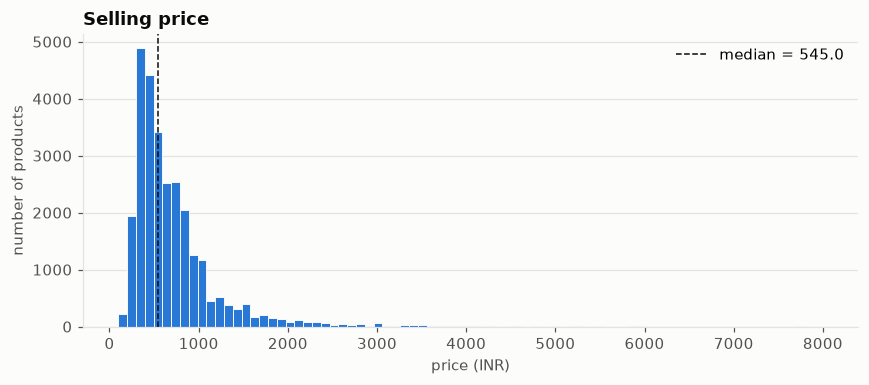

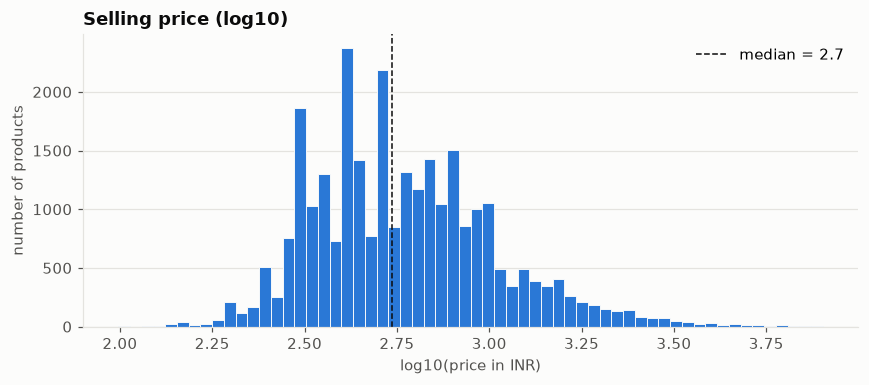

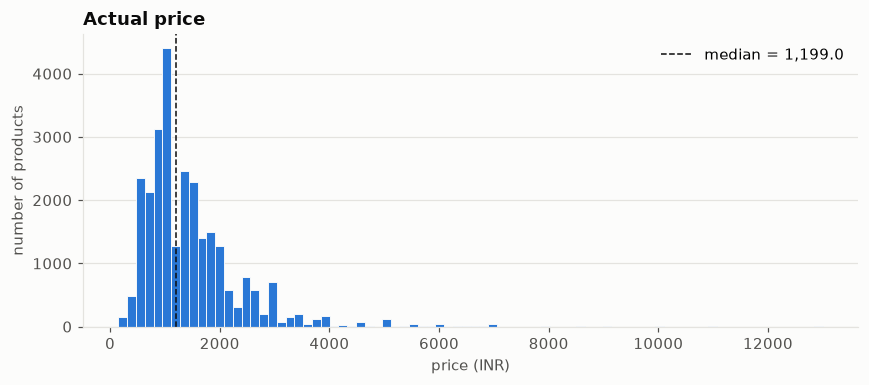

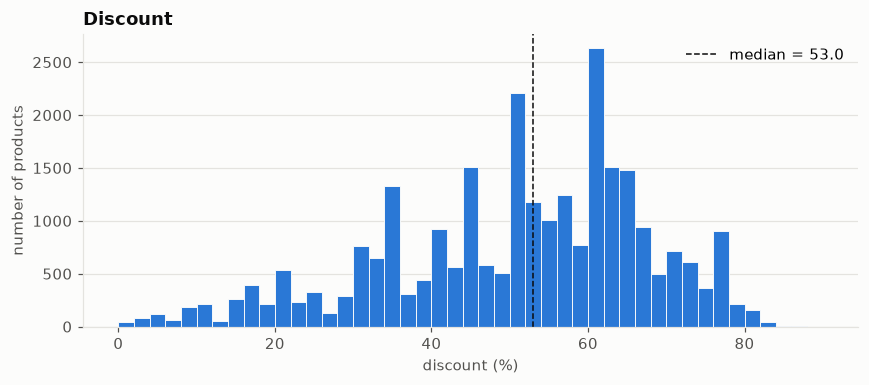

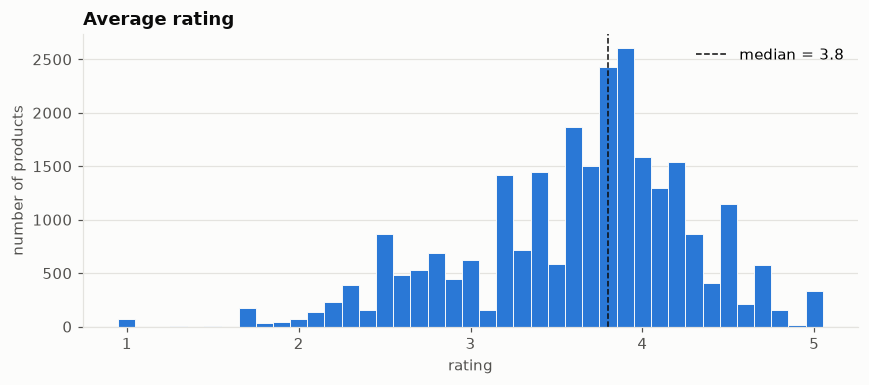

,out_of_stock,selling_price,discount,actual_price,average_rating
out_of_stock,1.00,0.14,-0.02,0.10,0.08
selling_price,0.14,1.00,-0.30,0.85,-0.01
discount,-0.02,-0.30,1.00,0.16,-0.05
actual_price,0.10,0.85,0.16,1.00,-0.03
average_rating,0.08,-0.01,-0.05,-0.03,1.00


In [34]:
hist(docs["selling_price"].dropna(), "Selling price", "price (INR)", "selling_price", bins=80)
hist(np.log10(docs["selling_price"].dropna()), "Selling price (log10)", "log10(price in INR)", "selling_price_log", bins=60)
hist(docs["actual_price"].dropna(), "Actual price", "price (INR)", "actual_price", bins=80)
hist(docs["discount"].dropna(), "Discount", "discount (%)", "discount", bins=range(0, 91, 2))
hist(docs["average_rating"].dropna(), "Average rating", "rating", "average_rating", bins=np.arange(0.95, 5.1, 0.1))
docs[NUMERIC_FIELDS].astype(float).corr().round(2)

### 6.8 Product rankings

Top and bottom products by rating, selling price and discount (ties broken by the column named in each heading).

In [35]:
show = ["title", "brand_full", "sub_category", "selling_price", "actual_price", "discount", "average_rating", "out_of_stock"]
rankings = {
    "Highest rated (ties: larger discount)": docs.sort_values(["average_rating", "discount"], ascending=[False, False]),
    "Lowest rated (ties: lower price)": docs.sort_values(["average_rating", "selling_price"], ascending=[True, True]),
    "Most expensive (selling price)": docs.sort_values("selling_price", ascending=False),
    "Cheapest (selling price)": docs.sort_values("selling_price", ascending=True),
    "Largest discount (ties: larger actual price)": docs.sort_values(["discount", "actual_price"], ascending=[False, False]),
}
for heading, ranked in rankings.items():
    display(Markdown(f"#### {heading}"))
    display(ranked[show].head(10))
print("products with rating 5.0:", (docs["average_rating"] == 5).sum(), " with rating 1.0:", (docs["average_rating"] == 1).sum())

#### Highest rated (ties: larger discount)

,title,brand_full,sub_category,selling_price,actual_price,discount,average_rating,out_of_stock
pid,,,,,,,,
KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),purple state,"Kurtas, Ethnic Sets and Bottoms",449.0,2599.0,82.0,5.0,False
BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),sayitloud,Innerwear and Swimwear,249.0,1149.0,78.0,5.0,False
TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvibes,Topwear,275.0,1200.0,77.0,5.0,False
TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,pixfab,Topwear,289.0,1299.0,77.0,5.0,False
TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,pixfab,Topwear,288.0,1299.0,77.0,5.0,True
TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,pixfab,Topwear,288.0,1299.0,77.0,5.0,True
TSHFTT2STQWNBH23,Printed Men Round Neck Blue T-Shirt,pixfab,Topwear,288.0,1299.0,77.0,5.0,True
TSHFTT2JUVYZFJZY,Solid Women Round Neck Yellow T-Shirt,pixfab,Topwear,288.0,1299.0,77.0,5.0,False
TSHFTT2SFXUT3N7F,Printed Women Round Neck Yellow T-Shirt,pixfab,Topwear,288.0,1299.0,77.0,5.0,False


#### Lowest rated (ties: lower price)

,title,brand_full,sub_category,selling_price,actual_price,discount,average_rating,out_of_stock
pid,,,,,,,,
SOCECUXJWFZRQD9D,Men Self Design Mid-Calf/Crew,welwear,Clothing Accessories,159.0,299.0,46.0,1.0,False
TSHFDVE8XCKVY8FH,Solid Women Round Neck Black T-Shirt,athliv,Topwear,241.0,799.0,69.0,1.0,False
CAPE93UNKKMTGY8Y,Self Design Skull Cap,graceway,Clothing Accessories,249.0,999.0,75.0,1.0,False
TSHEYQ73GQDVH2ZG,"Self Design Men V-Neck Black, Yellow T-Shirt",fairdeals,Topwear,279.0,1299.0,78.0,1.0,False
TSHEYRU47USHREYY,Solid Women Round or Crew Multicolor T-Shirt,fairdeals,Topwear,284.0,1299.0,78.0,1.0,False
SOCEUGUHTNM3FHDW,Women Peds/Footie/No-Show (Pack of 3),cotson,Clothing Accessories,288.0,599.0,51.0,1.0,False
BXREZM6K86C6PR8R,Checkered Men Boxer (Pack of 3),lucky roger,Innerwear and Swimwear,299.0,699.0,57.0,1.0,False
BXREZM62KEAFKF2Y,Checkered Women Boxer (Pack of 3),lucky roger,Innerwear and Swimwear,299.0,699.0,57.0,1.0,False
TSHFPH8KFPYDG8WP,Printed Men Round Neck Yellow T-Shirt,yellowvibes,Topwear,300.0,999.0,69.0,1.0,False


#### Most expensive (selling price)

...

#### Cheapest (selling price)

,title,brand_full,sub_category,selling_price,actual_price,discount,average_rating,out_of_stock
pid,,,,,,,,
BDAFUBD2EJHFCRNC,Men Printed Bandana,t10 sports,Clothing Accessories,99.0,199.0,50.0,2.4,False
SOCET7QRNHYG9HHB,Women Mid-Calf/Crew (Pack of 2),welwear,Clothing Accessories,99.0,199.0,50.0,3.8,False
SOCFFGA2FYZQBFXT,Women Color Block Ankle Length (Pack of 3),your shopping store,Clothing Accessories,118.0,499.0,76.0,3.9,False
SOCFZ7JX39ZEW8GE,Women Solid Ankle Length (Pack of 3),ina group,Clothing Accessories,120.0,399.0,69.0,NaN,False
SOCFZAGJC3VUFQU9,Women Solid Ankle Length (Pack of 3),ina group,Clothing Accessories,120.0,399.0,69.0,NaN,False
SOCFZ7GFAZGYZGR7,Men Solid Ankle Length (Pack of 3),ina group,Clothing Accessories,120.0,399.0,69.0,NaN,False
CAPEX5YHPH3MSGFC,Cotton 5 panel baseball Cap,t10 sports,Clothing Accessories,124.0,249.0,50.0,2.3,False
SUSECSFFVNKG5VGG,Brand Trunk Y- Back Suspenders for Men (Black),None,"Brand Trunk Bags, Wallets & Belts",125.0,499.0,74.0,4.1,False
TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,jack royal,Topwear,128.0,998.0,87.0,3.0,False


#### Largest discount (ties: larger actual price)

,title,brand_full,sub_category,selling_price,actual_price,discount,average_rating,out_of_stock
pid,,,,,,,,
TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,jack royal,Topwear,128.0,998.0,87.0,3.0,False
TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,jack royal,Topwear,136.0,999.0,86.0,4.1,True
TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,jack royal,Topwear,136.0,999.0,86.0,4.7,False
TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pack of 2),yellowvibes,Topwear,449.0,2999.0,85.0,3.2,False
CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),None,Clothing Accessories,499.0,3299.0,84.0,2.7,False
TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvibes,Topwear,280.0,1800.0,84.0,3.4,False
TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvibes,Topwear,282.0,1800.0,84.0,4.2,False
TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvibes,Topwear,230.0,1500.0,84.0,4.6,False
TSHFVM4PQPRY2CRZ,Color Block Women Round Neck Green T-Shirt,refro,Topwear,228.0,1499.0,84.0,4.2,False


products with rating 5.0: 329  with rating 1.0: 68


### 6.9 Out of stock

Stock-status distribution overall and by sub-category (sub-categories with at least 50 products), price / rating / discount by stock status, and stock status against missing `seller` / `actual_price`.

,products,share
out_of_stock,,
in stock,26436,94.15
out of stock,1644,5.85


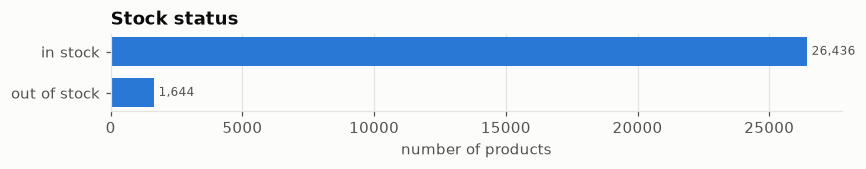

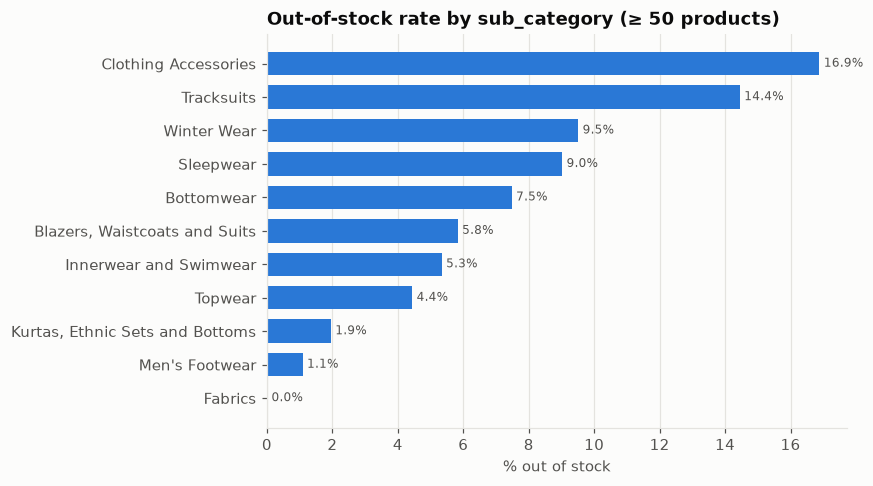

,products,mean_rating,median_price,mean_discount
out_of_stock,,,,
False,26436,3.62,539.0,50.34
True,1644,3.92,683.0,48.91


In [36]:
oos = docs["out_of_stock"].value_counts().rename({False: "in stock", True: "out of stock"})
display(oos.to_frame("products").assign(share=(100 * oos / oos.sum()).round(2)))
barh(oos, "Stock status", "number of products", "out_of_stock")
oos_by_sub = docs.groupby("sub_category")["out_of_stock"].agg(["mean", "size"])
oos_by_sub = oos_by_sub[oos_by_sub["size"] >= 50].sort_values("mean", ascending=False)["mean"] * 100
barh(oos_by_sub, "Out-of-stock rate by sub_category (≥ 50 products)", "% out of stock", "out_of_stock_by_sub_category",
     fmt="{:.1f}%")
docs.groupby("out_of_stock").agg(products=("pid", "size"), mean_rating=("average_rating", "mean"),
                                 median_price=("selling_price", "median"), mean_discount=("discount", "mean")).round(2)

In [37]:
pd.concat({"seller missing": pd.crosstab(docs["out_of_stock"], docs["seller"].isna().rename("missing")),
           "actual_price missing": pd.crosstab(docs["out_of_stock"], docs["actual_price"].isna().rename("missing"))}, axis=1)

seller missing       actual_price missing      
missing               False True                 False True 
out_of_stock                                                
False                 26436     0                25726   710
True                      1  1643                 1577    67

### 6.10 Named-entity recognition

spaCy `en_core_web_sm` (NER component only) on a fixed random sample of 5,000 products with a description, run on the descriptions and on the titles of the same sample.

entities in 5,000 descriptions: 14,155; in titles: 4,580


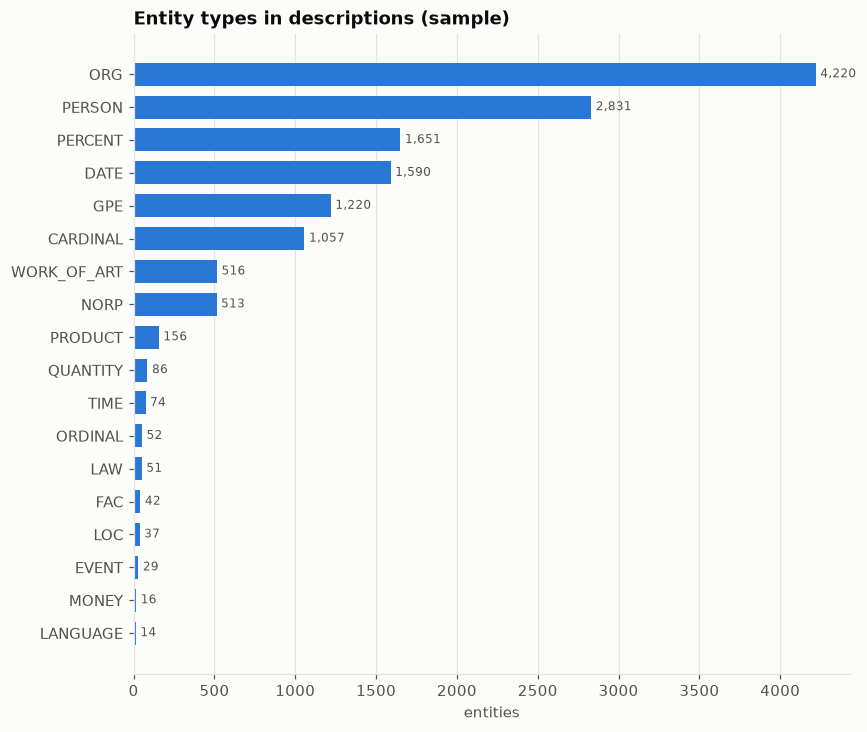

In [38]:
import spacy

NER_SAMPLE = 5000
nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer", "attribute_ruler", "tagger"])
sample = docs[docs["description"].notna()].sample(n=NER_SAMPLE, random_state=RANDOM_STATE)


def entities(texts):
    """Run spaCy NER on a Series of texts and return one row per entity (pid, text, label)."""
    rows = []
    for pid, doc in zip(texts.index, nlp.pipe(texts.map(fix_mojibake).tolist(), batch_size=256)):
        rows += [{"pid": pid, "text": ent.text.strip(), "label": ent.label_} for ent in doc.ents]
    return pd.DataFrame(rows)


ents_desc = entities(sample["description"])
ents_title = entities(sample["title"])
print(f"entities in {NER_SAMPLE:,} descriptions: {len(ents_desc):,}; in titles: {len(ents_title):,}")
ents_desc.to_csv(OUT_DIR / "ner_entities_sample.csv", index=False)
label_counts = ents_desc["label"].value_counts()
barh(label_counts, "Entity types in descriptions (sample)", "entities", "ner_labels")

Most frequent entities per type in descriptions and in titles.

In [39]:
def top_per_label(ents, n=8):
    """Most frequent (lower-cased) entity texts per entity label."""
    return (ents.assign(text=ents["text"].str.lower()).groupby("label")["text"]
            .agg(lambda s: ", ".join(f"{t} ({c})" for t, c in Counter(s).most_common(n))))


display(top_per_label(ents_desc).loc[label_counts.index].to_frame("most frequent entities (descriptions)"))
top_per_label(ents_title).to_frame("most frequent entities (titles)")

,most frequent entities (descriptions)
label,
ORG,"keoti (138), printed (117), the amazing comfort of a shoefly polo t-shirts (..."
PERSON,"casual wear (127), track pant (123), arbour (121), cotton (91), lucky bird (..."
PERCENT,"100% (875), 60% (331), 40% (320), 20% (23), 80% (19), 100 % (14), tees - 100..."
DATE,"daily (170), weekend (165), some days (164), all day (116), the day (107), w..."
GPE,"cotton (282), kurta (252), india (188), ladies (62), ldhsati (50), solid (49..."
CARDINAL,"half (199), one (137), 3 (111), 2 (102), two (97), 5 (40), 4 (35), thousands..."
WORK_OF_ART,"t shirt for men women (59), shirt for women women (56), comfort fit (27), re..."
NORP,"jeans (178), joggers (76), indian (48), stylish (28), elastic (25), regular ..."
PRODUCT,"round (44), everland (14), s-xxl (10), shirt (10), micromodal (9), exclusive..."


,most frequent entities (titles)
label,
CARDINAL,"2 (372), 3 (328), 4 (75), 5 (69), 1 (61), 6 (48), 8) (16), 12 (15)"
DATE,"2021 (5), 2008 (1), 1203 (1), 1307-10 (1), 3015 (1)"
FAC,"kerala traditional mundu (5), crew black (2)"
GPE,"kurta (23), maroon (16), silver (1), black (1), natali (1), sheny (1), orang..."
LOC,multi colour (3)
NORP,dhoti (1)
ORG,"printed men round neck black t-shirt (75), printed women round neck white (7..."
PERCENT,100% (16)
PERSON,"solid women (198), solid men polo neck (84), straight kurta (72), striped me..."


How often the product's brand, when it appears in its own description, is recognised as an ORG entity.

In [40]:
org = ents_desc[ents_desc["label"] == "ORG"].groupby("pid")["text"].agg(lambda s: {t.lower() for t in s})
with_brand = sample[sample["brand_full"].notna()]
mentioned = with_brand.apply(lambda r: r["brand_full"] in normalize_text(r["description"]), axis=1)
hit = with_brand.apply(lambda r: any(r["brand_full"] in normalize_text(e) for e in org.get(r["pid"], set())), axis=1)
print(f"brand (recovered name) mentioned in its description: {mentioned.mean():.1%}; "
      f"recognised inside an ORG entity when mentioned: {hit[mentioned].mean():.1%}")

brand (recovered name) mentioned in its description: 48.0%; recognised inside an ORG entity when mentioned: 39.4%


Structured attributes from `product_details` (colour, fabric, pattern, fit, sleeve), counted over the whole corpus.

In [41]:
attr_counts = {key: docs["product_details"].map(lambda d: d.get(key)).value_counts().head(10)
               for key in ["Color", "Fabric", "Pattern", "Fit", "Sleeve"]}
pd.concat({k: v.rename_axis("value").reset_index(name="products") for k, v in attr_counts.items()}, axis=1)

Color                       Fabric                      Pattern                   Fit                              Sleeve         
        value products               value products               value products        value products                      value products
0  Multicolor     2528        Cotton Blend    10635               Solid    11108      Regular    11835                Half Sleeve     7506
1        Blue     2172         Pure Cotton     4954             Printed     6875         Slim     3831                Full Sleeve     6372
2       Black     1951          Polycotton     2667         Self Design     1290     Slim Fit      572               Short Sleeve     3585
3        Grey     1247           Polyester     1246             Striped     1153  Regular Fit      290                 Sleeveless      988
4   Dark Blue      757               Denim      561           Checkered     1101     Tailored       32               3/4th Sleeve      233
5       White      709              Cotton      495         Color Block     1026      Regulor       26             Roll-up Sleeve      107
6       Green      492       Cotton Jersey      465       Graphic Print     1025     Slim fit       26                 3/4 Sleeve       22
7       Brown      434     Polyester Blend      427          Typography      513      Tapered       24    Full Sleeve, 3/4 Sleeve       13
8         Red      399               Rayon      392              Washed      150        Loose       20  Full Sleeve, Short Sleeve        7
9       Beige      323  Cotton Lycra Blend      372  Self Design, Solid       96      REGULOR       18                     Raglan        5

## 7. Saved files

In [42]:
for path in sorted([*FIG_DIR.glob("*.png"), *OUT_DIR.glob("*"), PROCESSED_PATH]):
    print(f"{str(path.relative_to(REPO_ROOT)):70} {path.stat().st_size / 1024:9.1f} KiB")

data/processed_corpus.jsonl                                              59898.6 KiB
project_progress/part_1/figures/actual_price.png                            30.2 KiB
project_progress/part_1/figures/all_terms_count.png                         34.7 KiB
project_progress/part_1/figures/average_rating.png                          27.5 KiB
project_progress/part_1/figures/description_word_count.png                  34.6 KiB
project_progress/part_1/figures/discount.png                                30.7 KiB
project_progress/part_1/figures/missing_values.png                          44.5 KiB
project_progress/part_1/figures/ner_labels.png                              67.0 KiB
project_progress/part_1/figures/out_of_stock.png                            19.9 KiB
project_progress/part_1/figures/out_of_stock_by_sub_category.png            69.8 KiB
project_progress/part_1/figures/product_details_keys.png                    89.0 KiB
project_progress/part_1/figures/selling_price.png                